In [ ]:
# importing dependencies
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import keras
from sklearn.model_selection import train_test_split
from keras.models import Sequential
from keras.layers import Input, Dense
from keras.utils import plot_model
from keras.optimizers import Adam

In [ ]:
data_y= np.load('/content/drive/MyDrive/data/final_y.npy',allow_pickle=True)

In [ ]:
data_X=np.load('/content/drive/MyDrive/data/final_x.npy')

In [ ]:
data_y=pd.DataFrame(data_y)
data_X=pd.DataFrame(data_X)

In [ ]:
data_X.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11988 entries, 0 to 11987
Columns: 30000 entries, 0 to 29999
dtypes: int64(30000)
memory usage: 2.7 GB


In [ ]:
data_y.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11988 entries, 0 to 11987
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   0       11988 non-null  object
dtypes: object(1)
memory usage: 93.8+ KB


In [ ]:
data_y=data_y.replace({'Fresh':1,'Rotten':0})

/tmp/ipykernel_1025/2761722391.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  data_y=data_y.replace({'Fresh':1,'Rotten':0})


In [ ]:
data_X.isnull().sum()

,0
0,0
1,0
2,0
3,0
4,0
...,...
29995,0
29996,0
29997,0
29998,0


In [ ]:
data_y.isnull().sum()

,0
0,0


In [ ]:
print(data_X.shape)
print(data_y.shape)

(11988, 30000)
(11988, 1)


In [ ]:


X_train, X_test, y_train, y_test = train_test_split(
    data_X,
    data_y,
    test_size=0.2,
    random_state=42,
    shuffle=True
)

In [ ]:
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(9590, 30000)
(2398, 30000)
(9590, 1)
(2398, 1)


In [ ]:
print(data_X.min().min())
print(data_X.max().max())

0
255


In [ ]:
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

print(X_train.shape)
print(X_train.min().min(), X_train.max().max())

(9590, 30000)
0.0 1.0


In [ ]:
# baseline architecture
model = Sequential([
    Input(shape=(30000,)),
    Dense(128, activation="relu"),

    Dense(64, activation="relu"),

    Dense(1, activation="sigmoid")
])

In [ ]:
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"])

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

In [ ]:
history = model.fit(
    X_train,
    y_train,
    epochs=20,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/20
240/240 ━━━━━━━━━━━━━━━━━━━━ 15s 55ms/step - accuracy: 0.5792 - loss: 1.0552 - val_accuracy: 0.6543 - val_loss: 0.6310
Epoch 2/20
240/240 ━━━━━━━━━━━━━━━━━━━━ 19s 51ms/step - accuracy: 0.6193 - loss: 0.7149 - val_accuracy: 0.5328 - val_loss: 0.8164
Epoch 3/20
240/240 ━━━━━━━━━━━━━━━━━━━━ 20s 50ms/step - accuracy: 0.6605 - loss: 0.6269 - val_accuracy: 0.7127 - val_loss: 0.5780
Epoch 4/20
240/240 ━━━━━━━━━━━━━━━━━━━━ 21s 52ms/step - accuracy: 0.6767 - loss: 0.5976 - val_accuracy: 0.6111 - val_loss: 0.6474
Epoch 5/20
240/240 ━━━━━━━━━━━━━━━━━━━━ 12s 52ms/step - accuracy: 0.6966 - loss: 0.5772 - val_accuracy: 0.6439 - val_loss: 0.6158
Epoch 6/20
240/240 ━━━━━━━━━━━━━━━━━━━━ 12s 48ms/step - accuracy: 0.7063 - loss: 0.5704 - val_accuracy: 0.7138 - val_loss: 0.5708
Epoch 7/20
240/240 ━━━━━━━━━━━━━━━━━━━━ 11s 48ms/step - accuracy: 0.6954 - loss: 0.5785 - val_accuracy: 0.7174 - val_loss: 0.5533
Epoch 8/20
240/240 ━━━━━━━━━━━━━━━━━━━━ 12s 51ms/step - accuracy: 0.7121 - loss: 0.5506 - 

In [ ]:
loss, accuracy = model.evaluate(X_test, y_test)

print("Test Loss:", loss)
print("Test Accuracy:", accuracy)

75/75 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.7168 - loss: 0.5513
Test Loss: 0.5513267517089844
Test Accuracy: 0.7168473601341248


Classification Report:
              precision    recall  f1-score   support

      Rotten       0.70      0.71      0.71      1148
       Fresh       0.73      0.72      0.73      1250

    accuracy                           0.72      2398
   macro avg       0.72      0.72      0.72      2398
weighted avg       0.72      0.72      0.72      2398



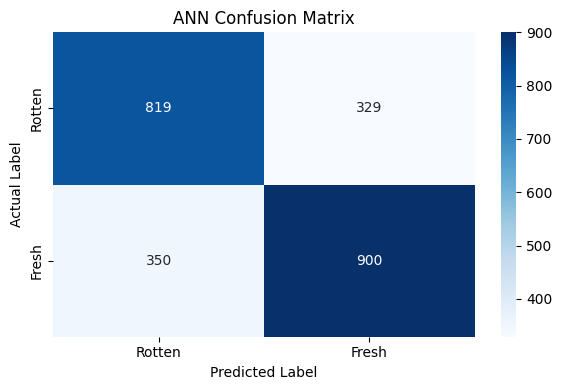

In [ ]:
from sklearn.metrics import confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Predict probabilities
y_prob = model.predict(X_test, verbose=0).ravel()

# Convert probabilities into class labels
# 0 = Rotten, 1 = Fresh
y_pred = (y_prob >= 0.5).astype(int)

# Actual labels
y_true = np.asarray(y_test).ravel().astype(int)

# Classification report
print("Classification Report:")
print(
    classification_report(
        y_true,
        y_pred,
        labels=[0, 1],
        target_names=["Rotten", "Fresh"],
        zero_division=0
    )
)

# Confusion matrix
cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

# Plot confusion matrix
plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Rotten", "Fresh"],
    yticklabels=["Rotten", "Fresh"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("ANN Confusion Matrix")
plt.tight_layout()
plt.show()

In [ ]:
print("Training Accuracy:", history.history["accuracy"][-1])
print("Validation Accuracy:", history.history["val_accuracy"][-1])
print("Training Loss:", history.history["loss"][-1])
print("Validation Loss:", history.history["val_loss"][-1])

Training Accuracy: 0.7213243246078491
Validation Accuracy: 0.6157455444335938
Training Loss: 0.5443328022956848
Validation Loss: 0.6550121307373047


In [ ]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

In [ ]:
model.save("model_ann.keras")